In [1]:
!pip install PyPDF2 nltk gensim wordcloud matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.6/232.6 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 29.5 MB/s eta 0:00:00


In [8]:
import PyPDF2
from gensim.models import LdaModel
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from gensim import corpora
from gensim.models import LsiModel
from gensim import similarities
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

nltk.download('punkt')
nltk.download('stopwords')


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [9]:

# Open the PDF file
pdf_file = open('Text_Mining.pdf', 'rb')

# Initialization
pdf_reader = PyPDF2.PdfReader(pdf_file)

# extract text from all pages
article_text = ''



In [10]:
import PyPDF2

with open('Text_Mining.pdf', 'rb') as pdf_file:
    pdf_reader = PyPDF2.PdfReader(pdf_file)

    article_text = ''
    for page in pdf_reader.pages:
        article_text += (page.extract_text() or '') + '\n'

print(len(article_text))   # vérifier que ce n'est pas 0
article_text[:500]

28982


'(IJACSA) International Journal of Advanced Computer Science and Applications,\nVol. 7 No. 11, 2016\nText Mining: Techniques, Applications and Issues\nRamzan Talib\x03, Muhammad Kashif Hanify, Shaeela Ayeshaz, and Fakeeha Fatimax\nDepartment of Computer Science,\nGovernment College University, Faisalabad, Pakistan\nAbstract —Rapid progress in digital data acquisition tech-\nniques have led to huge volume of data. More than 80 percent\nof today’s data is composed of unstructured or semi-structured\ndata. The '

In [11]:
# Tokenization and preprocessing
tokens = word_tokenize(article_text.lower())
tokens

['(',
 'ijacsa',
 ')',
 'international',
 'journal',
 'of',
 'advanced',
 'computer',
 'science',
 'and',
 'applications',
 ',',
 'vol',
 '.',
 '7',
 'no',
 '.',
 '11',
 ',',
 '2016',
 'text',
 'mining',
 ':',
 'techniques',
 ',',
 'applications',
 'and',
 'issues',
 'ramzan',
 'talib\x03',
 ',',
 'muhammad',
 'kashif',
 'hanify',
 ',',
 'shaeela',
 'ayeshaz',
 ',',
 'and',
 'fakeeha',
 'fatimax',
 'department',
 'of',
 'computer',
 'science',
 ',',
 'government',
 'college',
 'university',
 ',',
 'faisalabad',
 ',',
 'pakistan',
 'abstract',
 '—rapid',
 'progress',
 'in',
 'digital',
 'data',
 'acquisition',
 'tech-',
 'niques',
 'have',
 'led',
 'to',
 'huge',
 'volume',
 'of',
 'data',
 '.',
 'more',
 'than',
 '80',
 'percent',
 'of',
 'today',
 '’',
 's',
 'data',
 'is',
 'composed',
 'of',
 'unstructured',
 'or',
 'semi-structured',
 'data',
 '.',
 'the',
 'discovery',
 'of',
 'appropriate',
 'patterns',
 'and',
 'trends',
 'to',
 'analyze',
 'the',
 'text',
 'documents',
 'from',

In [12]:
# Tokenization and preprocessing
stop_words = set(stopwords.words('english'))
stop_words

{'a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 "he's",
 'her',
 'here',
 'hers',
 'herself',
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 "i'll",
 "i'm",
 "i've",
 'if',
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [13]:
# Stop words personnalisés ( add:computer /science // Remove :not no but)
from nltk.corpus import stopwords

# Liste de base (anglais)
stop_words = set(stopwords.words('english'))

# Ajouter des mots
stop_words.update(['computer', 'science'])

# Retirer des mots (discard ne plante pas si le mot est absent)
for mot in ['not', 'no', 'but']:
    stop_words.discard(mot)

# Vérification
print('computer' in stop_words)   # True
print('not' in stop_words)        # False

True
False


In [14]:
# Tokenization and preprocessing (letters or numbers)
filtered_tokens = [word for word in tokens if word.isalnum() and word not in stop_words]
filtered_tokens

['ijacsa',
 'international',
 'journal',
 'advanced',
 'applications',
 'vol',
 '7',
 'no',
 '11',
 '2016',
 'text',
 'mining',
 'techniques',
 'applications',
 'issues',
 'ramzan',
 'muhammad',
 'kashif',
 'hanify',
 'shaeela',
 'ayeshaz',
 'fakeeha',
 'fatimax',
 'department',
 'government',
 'college',
 'university',
 'faisalabad',
 'pakistan',
 'abstract',
 'progress',
 'digital',
 'data',
 'acquisition',
 'niques',
 'led',
 'huge',
 'volume',
 'data',
 '80',
 'percent',
 'today',
 'data',
 'composed',
 'unstructured',
 'data',
 'discovery',
 'appropriate',
 'patterns',
 'trends',
 'analyze',
 'text',
 'documents',
 'massive',
 'volume',
 'data',
 'big',
 'issue',
 'text',
 'mining',
 'process',
 'extracting',
 'interesting',
 'trivial',
 'patterns',
 'huge',
 'amount',
 'text',
 'documents',
 'exist',
 'different',
 'techniques',
 'tools',
 'mine',
 'text',
 'discover',
 'valuable',
 'information',
 'future',
 'prediction',
 'decision',
 'making',
 'process',
 'selection',
 'right

In [15]:
# Stemming
stemmer = PorterStemmer()
stemmed_tokens = [stemmer.stem(word) for word in filtered_tokens]
stemmed_tokens

['ijacsa',
 'intern',
 'journal',
 'advanc',
 'applic',
 'vol',
 '7',
 'no',
 '11',
 '2016',
 'text',
 'mine',
 'techniqu',
 'applic',
 'issu',
 'ramzan',
 'muhammad',
 'kashif',
 'hanifi',
 'shaeela',
 'ayeshaz',
 'fakeeha',
 'fatimax',
 'depart',
 'govern',
 'colleg',
 'univers',
 'faisalabad',
 'pakistan',
 'abstract',
 'progress',
 'digit',
 'data',
 'acquisit',
 'niqu',
 'led',
 'huge',
 'volum',
 'data',
 '80',
 'percent',
 'today',
 'data',
 'compos',
 'unstructur',
 'data',
 'discoveri',
 'appropri',
 'pattern',
 'trend',
 'analyz',
 'text',
 'document',
 'massiv',
 'volum',
 'data',
 'big',
 'issu',
 'text',
 'mine',
 'process',
 'extract',
 'interest',
 'trivial',
 'pattern',
 'huge',
 'amount',
 'text',
 'document',
 'exist',
 'differ',
 'techniqu',
 'tool',
 'mine',
 'text',
 'discov',
 'valuabl',
 'inform',
 'futur',
 'predict',
 'decis',
 'make',
 'process',
 'select',
 'right',
 'appropri',
 'text',
 'mine',
 'techniqu',
 'help',
 'enhanc',
 'speed',
 'decreas',
 'time',

In [16]:
# Stemming personnalisé rule-based appliqué à tout le texte (exp Computer : comp)

SUFFIXES = ['ational', 'ization', 'ations', 'ation', 'ement', 'ing',
            'ers', 'er', 'ed', 'ly', 'es', 's']

# Exceptions : forcer un stem précis
EXCEPTIONS = {
    'computer': 'comp',
    'computers': 'comp',
    'computing': 'comp',
    'computation': 'comp',
}

def custom_stem(word, min_len=3):
    # 1. Exceptions d'abord
    if word in EXCEPTIONS:
        return EXCEPTIONS[word]
    # 2. Règles de suffixes
    for suf in SUFFIXES:
        if word.endswith(suf) and len(word) - len(suf) >= min_len:
            return word[:-len(suf)]
    return word


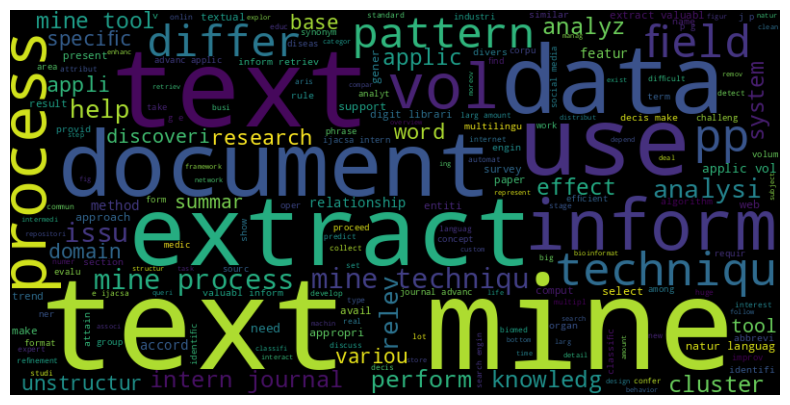

In [17]:
# Word Cloud
wordcloud = WordCloud(width=800, height=400).generate(' '.join(stemmed_tokens))
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()


In [18]:
# Create a dictionary from the stemmed tokens unique words
dictionary = corpora.Dictionary([stemmed_tokens])

In [19]:
for word, word_id in dictionary.token2id.items():
    print(f"Word: {word}, ID: {word_id}")

Word: 02, ID: 0
Word: 1, ID: 1
Word: 10, ID: 2
Word: 11, ID: 3
Word: 11th, ID: 4
Word: 12, ID: 5
Word: 13, ID: 6
Word: 14, ID: 7
Word: 145, ID: 8
Word: 15, ID: 9
Word: 16, ID: 10
Word: 168, ID: 11
Word: 17, ID: 12
Word: 18, ID: 13
Word: 19, ID: 14
Word: 2, ID: 15
Word: 20, ID: 16
Word: 2000, ID: 17
Word: 2004, ID: 18
Word: 2005, ID: 19
Word: 2006, ID: 20
Word: 2007, ID: 21
Word: 2009, ID: 22
Word: 2010, ID: 23
Word: 2011, ID: 24
Word: 2012, ID: 25
Word: 2013, ID: 26
Word: 2014, ID: 27
Word: 2015, ID: 28
Word: 2016, ID: 29
Word: 21, ID: 30
Word: 22, ID: 31
Word: 23, ID: 32
Word: 24, ID: 33
Word: 25, ID: 34
Word: 26, ID: 35
Word: 27, ID: 36
Word: 275, ID: 37
Word: 28, ID: 38
Word: 283, ID: 39
Word: 29, ID: 40
Word: 3, ID: 41
Word: 30, ID: 42
Word: 31, ID: 43
Word: 311, ID: 44
Word: 32, ID: 45
Word: 33, ID: 46
Word: 34, ID: 47
Word: 35, ID: 48
Word: 36, ID: 49
Word: 39, ID: 50
Word: 4, ID: 51
Word: 414, ID: 52
Word: 415, ID: 53
Word: 416, ID: 54
Word: 417, ID: 55
Word: 418, ID: 56
Word: 4

In [20]:
# Create a document-term matrix (bag-of-words  (word_id, word_frequency).)
corpus = [dictionary.doc2bow(stemmed_tokens)]
corpus

[[(0, 1),
  (1, 16),
  (2, 4),
  (3, 11),
  (4, 1),
  (5, 3),
  (6, 2),
  (7, 3),
  (8, 1),
  (9, 2),
  (10, 4),
  (11, 1),
  (12, 2),
  (13, 3),
  (14, 3),
  (15, 9),
  (16, 3),
  (17, 1),
  (18, 1),
  (19, 2),
  (20, 1),
  (21, 2),
  (22, 3),
  (23, 4),
  (24, 1),
  (25, 4),
  (26, 11),
  (27, 4),
  (28, 4),
  (29, 8),
  (30, 2),
  (31, 4),
  (32, 3),
  (33, 4),
  (34, 3),
  (35, 2),
  (36, 4),
  (37, 1),
  (38, 2),
  (39, 1),
  (40, 3),
  (41, 8),
  (42, 2),
  (43, 2),
  (44, 1),
  (45, 2),
  (46, 2),
  (47, 3),
  (48, 2),
  (49, 3),
  (50, 1),
  (51, 8),
  (52, 1),
  (53, 1),
  (54, 1),
  (55, 1),
  (56, 1),
  (57, 1),
  (58, 1),
  (59, 1),
  (60, 1),
  (61, 1),
  (62, 1),
  (63, 1),
  (64, 6),
  (65, 1),
  (66, 1),
  (67, 1),
  (68, 5),
  (69, 1),
  (70, 7),
  (71, 2),
  (72, 4),
  (73, 2),
  (74, 1),
  (75, 4),
  (76, 6),
  (77, 1),
  (78, 2),
  (79, 1),
  (80, 1),
  (81, 1),
  (82, 1),
  (83, 3),
  (84, 10),
  (85, 1),
  (86, 2),
  (87, 2),
  (88, 1),
  (89, 1),
  (90, 1),
  (91

different topic modeling techniques

In [21]:
#Latent Semantic Indexing (LSI)  # You can adjust the number of topics as needed
# Get the LSI topics
from gensim import corpora
from gensim.models import LsiModel

# 1. Dictionnaire et corpus (bag-of-words)
# gensim attend une liste de documents, chaque document étant une liste de tokens
documents = [stemmed_tokens]

dictionary = corpora.Dictionary(documents)
corpus = [dictionary.doc2bow(doc) for doc in documents]

# 2. Modèle LSI (vous pouvez changer le nombre de topics)
num_topics = 5
lsi_model = LsiModel(corpus, num_topics=num_topics, id2word=dictionary)

# 3. Afficher les topics LSI
for idx, topic in lsi_model.print_topics(num_topics=num_topics, num_words=8):
    print(f"Topic {idx}: {topic}")


Topic 0: 0.558*"text" + 0.424*"mine" + 0.206*"extract" + 0.180*"inform" + 0.180*"process" + 0.176*"techniqu" + 0.172*"use" + 0.168*"data"


In [22]:
# Latent Dirichlet Allocation (LDA)# You can adjust the number of topics and passes as needed
# LDA topics

from gensim.models import LdaModel

# Réutilise dictionary et corpus de l'étape LSI
num_topics = 5
passes = 10

lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=num_topics,
    passes=passes,
    random_state=42
)

# Afficher les topics LDA
for idx, topic in lda_model.print_topics(num_topics=num_topics, num_words=8):
    print(f"Topic {idx}: {topic}")

Topic 0: 0.044*"text" + 0.034*"mine" + 0.016*"extract" + 0.014*"inform" + 0.014*"process" + 0.014*"techniqu" + 0.014*"use" + 0.013*"data"
Topic 1: 0.002*"text" + 0.002*"mine" + 0.002*"process" + 0.002*"extract" + 0.002*"document" + 0.001*"use" + 0.001*"inform" + 0.001*"techniqu"
Topic 2: 0.002*"text" + 0.002*"mine" + 0.002*"process" + 0.002*"extract" + 0.002*"inform" + 0.002*"techniqu" + 0.002*"document" + 0.002*"data"
Topic 3: 0.002*"text" + 0.002*"mine" + 0.002*"inform" + 0.001*"use" + 0.001*"data" + 0.001*"process" + 0.001*"techniqu" + 0.001*"document"
Topic 4: 0.002*"text" + 0.002*"mine" + 0.001*"extract" + 0.001*"process" + 0.001*"document" + 0.001*"techniqu" + 0.001*"inform" + 0.001*"use"


In [ ]:
# + pos / NER / TextCategorizer /distance de levenshtein ...

In [23]:
#installation:
!pip install spacy
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 89.5 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [24]:
nltk.download('averaged_perceptron_tagger_eng')

texte = article_text[:1000]          # un extrait suffit pour tester
tokens_bruts = word_tokenize(texte)
pos_tags = nltk.pos_tag(tokens_bruts)
print(pos_tags[:20])

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


[('(', '('), ('IJACSA', 'NNP'), (')', ')'), ('International', 'NNP'), ('Journal', 'NNP'), ('of', 'IN'), ('Advanced', 'NNP'), ('Computer', 'NNP'), ('Science', 'NNP'), ('and', 'CC'), ('Applications', 'NNP'), (',', ','), ('Vol', 'NNP'), ('.', '.'), ('7', 'CD'), ('No', 'NNP'), ('.', '.'), ('11', 'CD'), (',', ','), ('2016', 'CD')]


In [25]:
from collections import Counter
print(Counter(tag for _, tag in pos_tags).most_common(10))

[('NNP', 33), ('NN', 30), ('JJ', 17), ('IN', 15), ('NNS', 15), ('CC', 12), (',', 9), ('DT', 8), ('.', 7), ('VBZ', 5)]


In [26]:
#NER (spaCy)
import spacy
nlp = spacy.load('en_core_web_sm')

doc = nlp(article_text[:5000])       # limiter la taille pour aller vite
for ent in doc.ents[:20]:
    print(ent.text, '->', ent.label_)

# Comptage par type d'entité
print(Counter(ent.label_ for ent in doc.ents))

International Journal of Advanced Computer Science and Applications -> ORG
Muhammad Kashif Hanify -> PERSON
Shaeela Ayeshaz -> PERSON
Fakeeha Fatimax -> PERSON
Department of Computer Science -> ORG
Government College University -> ORG
Faisalabad -> GPE
Pakistan -> GPE
More than 80 percent -> PERCENT
today -> DATE
Discovery -> PRODUCT
Information Extraction -> ORG
1 -> CARDINAL
2 -> CARDINAL
3 -> CARDINAL
3 -> CARDINAL
1 -> CARDINAL
Venn -> PERSON
4 -> CARDINAL
5 -> CARDINAL
Counter({'CARDINAL': 17, 'PERSON': 7, 'ORG': 6, 'GPE': 2, 'DATE': 2, 'PERCENT': 1, 'PRODUCT': 1})


In [27]:
from spacy import displacy
displacy.render(doc[:200].as_doc(), style='ent', jupyter=True)

In [28]:
#TextCategorizer (spaCy)
import spacy
from spacy.training import Example

nlp_cat = spacy.blank('en')
textcat = nlp_cat.add_pipe('textcat')   # une seule étiquette exclusive par texte
textcat.add_label('TECH')
textcat.add_label('AUTRE')

train_data = [
    ("text mining extracts patterns from documents", {"cats": {"TECH": 1, "AUTRE": 0}}),
    ("machine learning models classify data",        {"cats": {"TECH": 1, "AUTRE": 0}}),
    ("the weather is nice today",                    {"cats": {"TECH": 0, "AUTRE": 1}}),
    ("she went to the market to buy fruit",          {"cats": {"TECH": 0, "AUTRE": 1}}),
]

examples = [Example.from_dict(nlp_cat.make_doc(t), ann) for t, ann in train_data]
nlp_cat.initialize(lambda: examples)

import random
for epoch in range(20):
    random.shuffle(examples)
    losses = {}
    nlp_cat.update(examples, losses=losses)

print(nlp_cat("topic modeling with LDA").cats)

{'TECH': 0.5577924847602844, 'AUTRE': 0.4422074854373932}


In [29]:
#Distance de Levenshtein
def levenshtein(a, b):
    m, n = len(a), len(b)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(m + 1):
        dp[i][0] = i
    for j in range(n + 1):
        dp[0][j] = j
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            cout = 0 if a[i-1] == b[j-1] else 1
            dp[i][j] = min(dp[i-1][j] + 1,        # suppression
                           dp[i][j-1] + 1,        # insertion
                           dp[i-1][j-1] + cout)   # substitution
    return dp[m][n]

print(levenshtein('kitten', 'sitting'))   # 3

3


In [30]:
from nltk.metrics import edit_distance
print(edit_distance('kitten', 'sitting'))

3


In [31]:
vocabulaire = set(filtered_tokens)

def mots_proches(mot, n=5):
    return sorted(vocabulaire, key=lambda w: edit_distance(mot, w))[:n]

print(mots_proches('mining'))

['mining', 'meaning', 'making', 'minimum', 'king']
